In [1]:
import re
import numpy as np
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score
)

print("All libraries and evaluation metrics imported successfully.")

All libraries and evaluation metrics imported successfully.


In [2]:
dataset = "Dataset-SA.csv"

try:
    raw_reviews_df = pd.read_csv(dataset, encoding="utf-8")
    print("Loaded dataset using utf-8 encoding.")
except UnicodeDecodeError:
    raw_reviews_df = pd.read_csv(dataset, encoding="latin-1")
    print("utf-8 hit an encoding issue, so loaded dataset using latin-1 encoding.")

print("Dataset Shape:", raw_reviews_df.shape)

Loaded dataset using utf-8 encoding.
Dataset Shape: (205052, 6)


In [3]:
print("Columns in dataset:", raw_reviews_df.columns.tolist())
print("\nMissing values count:\n", raw_reviews_df.isnull().sum())
print("\nFirst 5 rows:\n", raw_reviews_df.head())

Columns in dataset: ['product_name', 'product_price', 'Rate', 'Review', 'Summary', 'Sentiment']

Missing values count:
 product_name         0
product_price        0
Rate                 0
Review           24664
Summary             11
Sentiment            0
dtype: int64

First 5 rows:
                                         product_name product_price Rate  \
0  Candes 12 L Room/Personal Air Cooler??????(Whi...          3999    5   
1  Candes 12 L Room/Personal Air Cooler??????(Whi...          3999    5   
2  Candes 12 L Room/Personal Air Cooler??????(Whi...          3999    3   
3  Candes 12 L Room/Personal Air Cooler??????(Whi...          3999    1   
4  Candes 12 L Room/Personal Air Cooler??????(Whi...          3999    3   

            Review                                            Summary  \
0           super!  great cooler excellent air flow and for this p...   
1          awesome              best budget 2 fit cooler nice cooling   
2             fair  the quality is good but

In [4]:
clean_reviews_df = raw_reviews_df.copy()

clean_reviews_df["Rate"] = pd.to_numeric(clean_reviews_df["Rate"], errors="coerce")
clean_reviews_df = clean_reviews_df[clean_reviews_df["Rate"].isin([1, 2, 3, 4, 5])].copy()
clean_reviews_df["Rate"] = clean_reviews_df["Rate"].astype(int)

clean_reviews_df["Review"] = clean_reviews_df["Review"].fillna("").astype(str).str.strip()
clean_reviews_df["Summary"] = clean_reviews_df["Summary"].fillna("").astype(str).str.strip()
clean_reviews_df["product_name"] = (
    clean_reviews_df["product_name"].fillna("Unknown Product").astype(str).str.strip()
)

clean_reviews_df["combined_review_text"] = np.where(
    clean_reviews_df["Summary"] != "",
    clean_reviews_df["Review"] + ". " + clean_reviews_df["Summary"],
    clean_reviews_df["Review"]
)

def clean_text_entry(text_value):
    without_tags = re.sub(r"<[^>]+>", " ", text_value)
    ascii_only = re.sub(r"[^\x00-\x7F]+", " ", without_tags)
    normalized_spaces = re.sub(r"\s+", " ", ascii_only).strip()
    return normalized_spaces

clean_reviews_df["clean_review_text"] = clean_reviews_df["combined_review_text"].apply(clean_text_entry)
clean_reviews_df = clean_reviews_df[clean_reviews_df["clean_review_text"].str.len() >= 5].copy()
clean_reviews_df = clean_reviews_df.drop_duplicates(
    subset=["product_name", "clean_review_text"]
).reset_index(drop=True)

parsed_price_strings = (
    clean_reviews_df["product_price"]
    .astype(str)
    .str.replace(r"[^\d.]", "", regex=True)
)
clean_reviews_df["price_inr"] = pd.to_numeric(parsed_price_strings, errors="coerce")
median_price_inr = clean_reviews_df["price_inr"].median()
clean_reviews_df["price_inr"] = clean_reviews_df["price_inr"].fillna(median_price_inr)

def assign_urgency_label(star_rating):
    if star_rating in [1, 2]:
        return 2
    elif star_rating == 3:
        return 1
    else:
        return 0

urgency_label_names = {
    0: "Positive / Low Urgency",
    1: "Neutral / Medium Urgency",
    2: "Negative / High Urgency"
}

clean_reviews_df["urgency_label"] = clean_reviews_df["Rate"].apply(assign_urgency_label)
clean_reviews_df["urgency_category"] = clean_reviews_df["urgency_label"].map(urgency_label_names)

print("Cleaned Dataset Shape:", clean_reviews_df.shape)
print("\nUrgency Class Counts:\n", clean_reviews_df["urgency_category"].value_counts())
print("\nPrice (INR) Summary:\n", clean_reviews_df["price_inr"].describe())

Cleaned Dataset Shape: (167173, 11)

Urgency Class Counts:
 urgency_category
Positive / Low Urgency      127812
Negative / High Urgency      25626
Neutral / Medium Urgency     13735
Name: count, dtype: int64

Price (INR) Summary:
 count    167173.000000
mean       4554.640498
std       10333.541804
min          59.000000
25%         349.000000
50%         890.000000
75%        3499.000000
max       86990.000000
Name: price_inr, dtype: float64


Univariate Summary - Star Ratings (Rate):
Rate
1    19615
2     6011
3    13735
4    32438
5    95374
Name: count, dtype: int64

Univariate Summary - Price in INR:
count    167173.000000
mean       4554.640498
std       10333.541804
min          59.000000
25%         349.000000
50%         890.000000
75%        3499.000000
max       86990.000000
Name: price_inr, dtype: float64


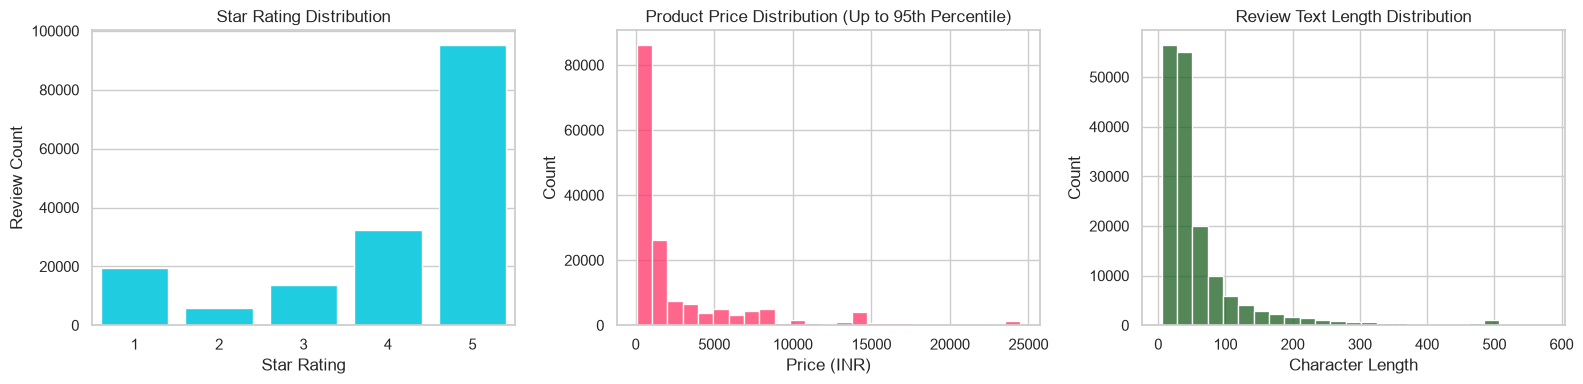

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

clean_reviews_df["review_char_length"] = clean_reviews_df["clean_review_text"].str.len()

print("Univariate Summary - Star Ratings (Rate):")
print(clean_reviews_df["Rate"].value_counts().sort_index())

print("\nUnivariate Summary - Price in INR:")
print(clean_reviews_df["price_inr"].describe())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(data=clean_reviews_df, x="Rate", ax=axes[0], color="#00E5FF")
axes[0].set_title("Star Rating Distribution")
axes[0].set_xlabel("Star Rating")
axes[0].set_ylabel("Review Count")

sns.histplot(
    data=clean_reviews_df[clean_reviews_df["price_inr"] <= clean_reviews_df["price_inr"].quantile(0.95)],
    x="price_inr",
    bins=25,
    ax=axes[1],
    color="#FF3366"
)
axes[1].set_title("Product Price Distribution (Up to 95th Percentile)")
axes[1].set_xlabel("Price (INR)")
axes[1].set_ylabel("Count")

sns.histplot(
    data=clean_reviews_df[clean_reviews_df["review_char_length"] <= 600],
    x="review_char_length",
    bins=25,
    ax=axes[2],
    color="#1B5E20"
)
axes[2].set_title("Review Text Length Distribution")
axes[2].set_xlabel("Character Length")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

Average Price (INR) by Urgency Category:
urgency_category
Negative / High Urgency     3031.86
Neutral / Medium Urgency    3250.54
Positive / Low Urgency      5000.10
Name: price_inr, dtype: float64

Average Review Character Length by Urgency Category:
urgency_category
Negative / High Urgency     72.72
Neutral / Medium Urgency    58.03
Positive / Low Urgency      60.80
Name: review_char_length, dtype: float64


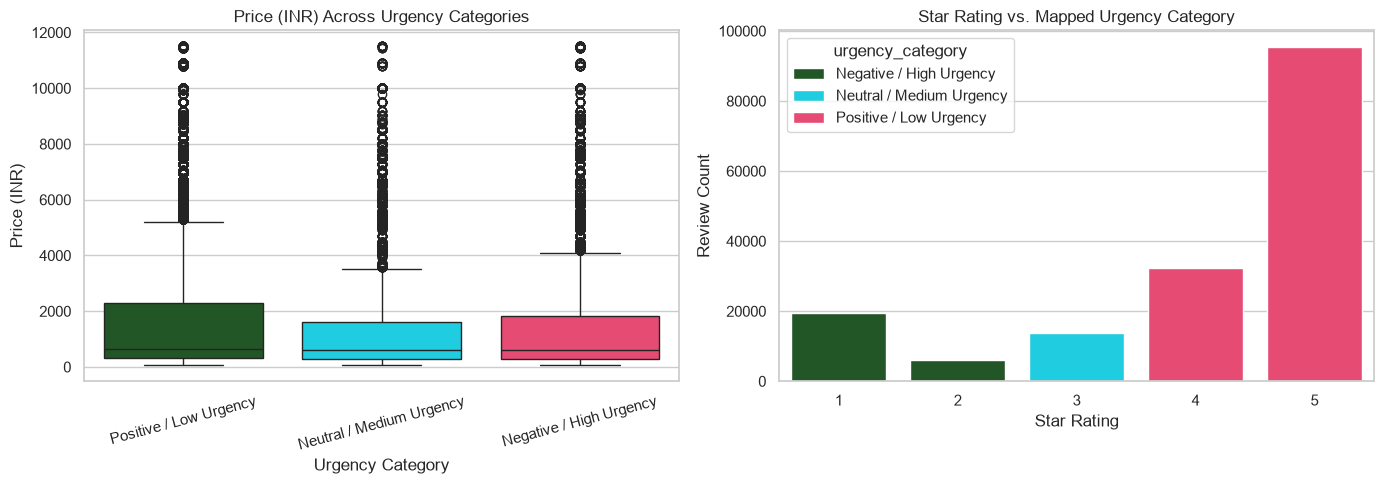

In [15]:
print("Average Price (INR) by Urgency Category:")
print(clean_reviews_df.groupby("urgency_category")["price_inr"].mean().round(2))

print("\nAverage Review Character Length by Urgency Category:")
print(clean_reviews_df.groupby("urgency_category")["review_char_length"].mean().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=clean_reviews_df[clean_reviews_df["price_inr"] <= clean_reviews_df["price_inr"].quantile(0.90)],
    x="urgency_category",
    y="price_inr",
    hue="urgency_category",
    palette=["#1B5E20", "#00E5FF", "#FF3366"],
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Price (INR) Across Urgency Categories")
axes[0].set_xlabel("Urgency Category")
axes[0].set_ylabel("Price (INR)")
axes[0].tick_params(axis="x", rotation=15)

sns.countplot(
    data=clean_reviews_df,
    x="Rate",
    hue="urgency_category",
    palette=["#1B5E20", "#00E5FF", "#FF3366"],
    ax=axes[1]
)
axes[1].set_title("Star Rating vs. Mapped Urgency Category")
axes[1].set_xlabel("Star Rating")
axes[1].set_ylabel("Review Count")

plt.tight_layout()
plt.show()

Correlation Matrix Across Key Numeric Features:

                     Rate  urgency_label  price_inr  review_char_length  \
Rate                1.000         -0.952      0.077              -0.052   
urgency_label      -0.952          1.000     -0.075               0.050   
price_inr           0.077         -0.075      1.000               0.196   
review_char_length -0.052          0.050      0.196               1.000   
delivery_days_sim  -0.002          0.002     -0.002              -0.002   

                    delivery_days_sim  
Rate                           -0.002  
urgency_label                   0.002  
price_inr                      -0.002  
review_char_length             -0.002  
delivery_days_sim               1.000  


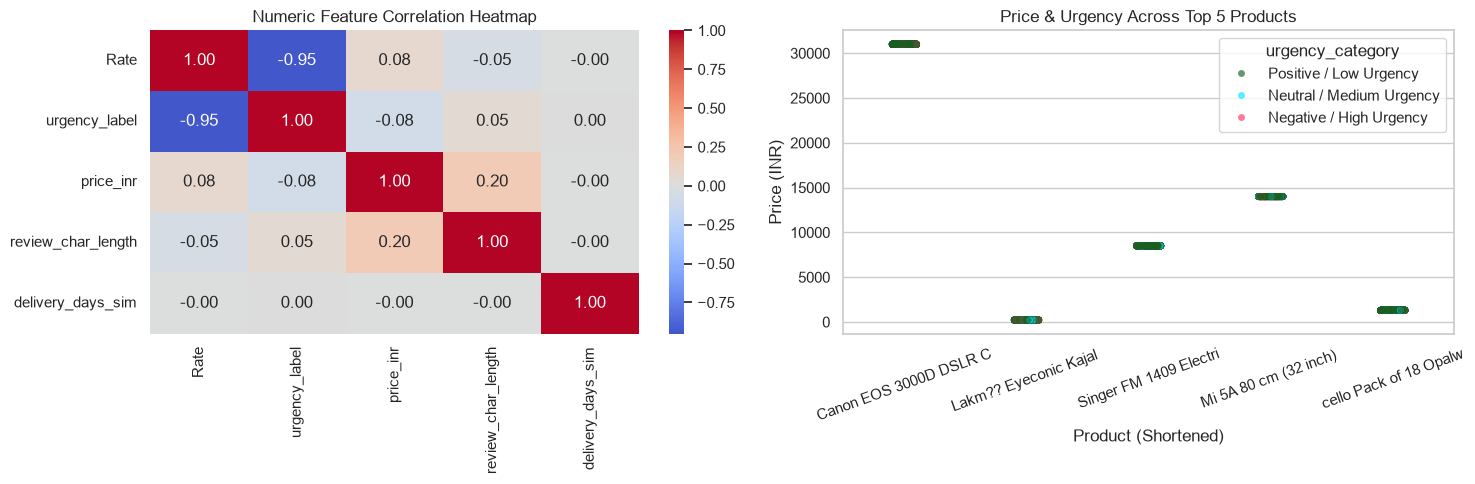

In [16]:
eda_multivariate_df = clean_reviews_df.copy()
eda_multivariate_df["delivery_days_sim"] = np.random.default_rng(42).integers(
    1, 15, size=len(eda_multivariate_df)
)

numeric_cols = ["Rate", "urgency_label", "price_inr", "review_char_length", "delivery_days_sim"]
correlation_matrix = eda_multivariate_df[numeric_cols].corr()

print("Correlation Matrix Across Key Numeric Features:\n")
print(correlation_matrix.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=axes[0]
)
axes[0].set_title("Numeric Feature Correlation Heatmap")

top_products = eda_multivariate_df["product_name"].value_counts().head(5).index
top_prod_df = eda_multivariate_df[eda_multivariate_df["product_name"].isin(top_products)].copy()
top_prod_df["short_product"] = top_prod_df["product_name"].str.slice(0, 22)

sns.stripplot(
    data=top_prod_df,
    x="short_product",
    y="price_inr",
    hue="urgency_category",
    palette=["#1B5E20", "#00E5FF", "#FF3366"],
    alpha=0.65,
    ax=axes[1]
)
axes[1].set_title("Price & Urgency Across Top 5 Products")
axes[1].set_xlabel("Product (Shortened)")
axes[1].set_ylabel("Price (INR)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [5]:
train_reviews_df, temp_reviews_df = train_test_split(
    clean_reviews_df,
    test_size=0.20,
    random_state=42,
    stratify=clean_reviews_df["urgency_label"]
)

val_reviews_df, test_reviews_df = train_test_split(
    temp_reviews_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_reviews_df["urgency_label"]
)

print("Train Shape:", train_reviews_df.shape)
print("Validation Shape:", val_reviews_df.shape)
print("Test Shape:", test_reviews_df.shape)

Train Shape: (133738, 11)
Validation Shape: (16717, 11)
Test Shape: (16718, 11)


In [6]:
sample_count = min(1000, len(test_reviews_df))
bulk_sample_df = test_reviews_df.sample(n=sample_count, random_state=42).copy()

random_gen = np.random.default_rng(42)
bulk_sample_df["days_since_delivery"] = random_gen.integers(1, 15, size=len(bulk_sample_df))

unlabeled_bulk_df = bulk_sample_df[
    ["product_name", "price_inr", "days_since_delivery", "clean_review_text"]
].rename(columns={"clean_review_text": "review_text"})

train_reviews_df.to_csv("train_clean.csv", index=False, encoding="utf-8")
val_reviews_df.to_csv("val_clean.csv", index=False, encoding="utf-8")
test_reviews_df.to_csv("test_clean.csv", index=False, encoding="utf-8")
unlabeled_bulk_df.to_csv("sample_unlabeled_1000.csv", index=False, encoding="utf-8")

print("Unlabeled Bulk Sample Shape:", unlabeled_bulk_df.shape)
print("Saved train_clean.csv, val_clean.csv, test_clean.csv, and sample_unlabeled_1000.csv.")
print("\nPreview of Unlabeled Bulk CSV:\n", unlabeled_bulk_df.head(3))

Unlabeled Bulk Sample Shape: (1000, 4)
Saved train_clean.csv, val_clean.csv, test_clean.csv, and sample_unlabeled_1000.csv.

Preview of Unlabeled Bulk CSV:
                                             product_name  price_inr  \
84635  TP-Link Archer C20 AC WiFi 750 MBPS Wireless R...       1599   
19801  BAJAJ Crest Neo 1200 mm 3 Blade Ceiling Fan???...       1329   
92629  boAt Wave Neo with 1.69 inch , 2.5D Curved Dis...       1699   

       days_since_delivery                                        review_text  
84635                    2  not recommended at all. very very good product...  
19801                   11               expected a better product. very slow  
92629                   10                    perfect product!. its very good  


In [7]:
def prepare_single_split(source_df, random_seed=42):
    prepared_df = source_df.copy()
    local_rng = np.random.default_rng(random_seed)
    if "days_since_delivery" not in prepared_df.columns:
        prepared_df["days_since_delivery"] = local_rng.integers(1, 15, size=len(prepared_df))
    prepared_df["product_label_short"] = (
        prepared_df["product_name"].astype(str).str.slice(0, 40)
    )
    return prepared_df

train_ready_df = prepare_single_split(train_reviews_df, random_seed=42)
val_ready_df = prepare_single_split(val_reviews_df, random_seed=43)
test_ready_df = prepare_single_split(test_reviews_df, random_seed=44)

print("Prepared train, validation, and test tables successfully.")
print("Sample columns:", train_ready_df[["product_label_short", "price_inr", "days_since_delivery"]].head(3))

Prepared train, validation, and test tables successfully.
Sample columns:                              product_label_short  price_inr  \
158572  Woodbuzz Engineered Wood Study TableFree      14146   
17575   Seagate One Touch with Password Protecti       5599   
5880    Canon EOS 3000D DSLR Camera 1 Camera Bod      30999   

        days_since_delivery  
158572                    2  
17575                    11  
5880                     10  


In [8]:
selected_features = [
    "clean_review_text",
    "price_inr",
    "days_since_delivery",
    "product_label_short"
]
target_col = "urgency_label"

X_train = train_ready_df[selected_features]
y_train = train_ready_df[target_col]

X_val = val_ready_df[selected_features]
y_val = val_ready_df[target_col]

X_test = test_ready_df[selected_features]
y_test = test_ready_df[target_col]

print("X_train Shape:", X_train.shape)
print("X_val Shape:", X_val.shape)
print("X_test Shape:", X_test.shape)
print("Target classes:", sorted(y_train.unique().tolist()))

X_train Shape: (133738, 4)
X_val Shape: (16717, 4)
X_test Shape: (16718, 4)
Target classes: [0, 1, 2]


In [10]:
text_transformer = TfidfVectorizer(
    max_features=4000,
    ngram_range=(1, 2),
    stop_words="english"
)

numeric_transformer = StandardScaler()

product_transformer = OneHotEncoder(
    handle_unknown="ignore",
    max_categories=50
)

feature_preprocessor = ColumnTransformer(
    transformers=[
        ("review_text_tfidf", text_transformer, "clean_review_text"),
        ("numeric_scaled", numeric_transformer, ["price_inr", "days_since_delivery"]),
        ("product_encoded", product_transformer, ["product_label_short"])
    ]
)

print("ColumnTransformer preprocessor is ready for model pipelines.")

ColumnTransformer preprocessor is ready for model pipelines.


In [12]:
from sklearn.ensemble import (
    ExtraTreesClassifier,
    VotingClassifier,
    StackingClassifier
)

base_lr = LogisticRegression(max_iter=500, random_state=42)
base_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=16,
    random_state=42,
    n_jobs=-1
)
base_et = ExtraTreesClassifier(
    n_estimators=100,
    max_depth=16,
    random_state=42,
    n_jobs=-1
)

weighted_voting_clf = VotingClassifier(
    estimators=[
        ("lr", base_lr),
        ("rf", base_rf),
        ("et", base_et)
    ],
    voting="soft",
    weights=[1, 2, 2]
)

stacking_clf = StackingClassifier(
    estimators=[
        ("lr", base_lr),
        ("rf", base_rf),
        ("et", base_et)
    ],
    final_estimator=LogisticRegression(max_iter=500, random_state=42),
    cv=3,
    n_jobs=-1
)

model_candidates = {
    "Logistic Regression": base_lr,
    "Decision Tree": DecisionTreeClassifier(max_depth=12, random_state=42),
    "Random Forest": base_rf,
    "Extra Trees": base_et,
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Weighted Voting": weighted_voting_clf,
    "Stacking Ensemble": stacking_clf
}

trained_model_pipelines = {}

for model_label, model_estimator in model_candidates.items():
    model_pipeline = Pipeline(
        steps=[
            ("preprocessor", feature_preprocessor),
            ("classifier", model_estimator)
        ]
    )
    model_pipeline.fit(X_train, y_train)
    trained_model_pipelines[model_label] = model_pipeline
    print("Trained model:", model_label)

Trained model: Logistic Regression
Trained model: Decision Tree
Trained model: Random Forest
Trained model: Extra Trees
Trained model: Gradient Boosting
Trained model: Weighted Voting
Trained model: Stacking Ensemble


In [13]:
validation_results = []

for model_label, trained_pipeline in trained_model_pipelines.items():
    val_pred_labels = trained_pipeline.predict(X_val)
    val_acc = accuracy_score(y_val, val_pred_labels)
    val_f1 = f1_score(y_val, val_pred_labels, average="weighted")

    validation_results.append({
        "Model": model_label,
        "Val_Accuracy": round(val_acc, 4),
        "Val_Weighted_F1": round(val_f1, 4)
    })

results_summary_df = pd.DataFrame(validation_results).sort_values(
    by="Val_Weighted_F1",
    ascending=False
).reset_index(drop=True)

print("Validation Comparison Table:\n")
print(results_summary_df)

winning_model_name = results_summary_df.loc[0, "Model"]
winning_model_pipeline = trained_model_pipelines[winning_model_name]

print("\nBest model based on Validation Weighted F1:", winning_model_name)

Validation Comparison Table:

                 Model  Val_Accuracy  Val_Weighted_F1
0    Stacking Ensemble        0.9577           0.9562
1  Logistic Regression        0.9570           0.9551
2    Gradient Boosting        0.9409           0.9371
3        Decision Tree        0.9076           0.9001
4      Weighted Voting        0.8820           0.8633
5        Random Forest        0.8463           0.8084
6          Extra Trees        0.7796           0.6958

Best model based on Validation Weighted F1: Stacking Ensemble


In [17]:
test_pred_labels = winning_model_pipeline.predict(X_test)
test_pred_probs = winning_model_pipeline.predict_proba(X_test)

test_acc = accuracy_score(y_test, test_pred_labels)
test_f1 = f1_score(y_test, test_pred_labels, average="weighted")

print("Winning Model Evaluated on Test Set:", winning_model_name)
print("Test Accuracy:", round(test_acc, 4))
print("Test Weighted F1:", round(test_f1, 4))

Winning Model Evaluated on Test Set: Stacking Ensemble
Test Accuracy: 0.957
Test Weighted F1: 0.9554


In [18]:
target_class_names = [
    "Positive / Low Urgency",
    "Neutral / Medium Urgency",
    "Negative / High Urgency"
]

print("Classification Report on Test Set:\n")
print(classification_report(y_test, test_pred_labels, target_names=target_class_names))

print("Confusion Matrix on Test Set:\n")
print(confusion_matrix(y_test, test_pred_labels))

Classification Report on Test Set:

                          precision    recall  f1-score   support

  Positive / Low Urgency       0.97      0.99      0.98     12782
Neutral / Medium Urgency       0.88      0.70      0.78      1373
 Negative / High Urgency       0.95      0.93      0.94      2563

                accuracy                           0.96     16718
               macro avg       0.93      0.88      0.90     16718
            weighted avg       0.96      0.96      0.96     16718

Confusion Matrix on Test Set:

[[12640    89    53]
 [  327   967    79]
 [  126    45  2392]]


In [19]:
scored_test_df = test_ready_df.copy()
scored_test_df["predicted_urgency_label"] = test_pred_labels
scored_test_df["predicted_urgency_category"] = scored_test_df["predicted_urgency_label"].map(
    urgency_label_names
)

high_urgency_prob = test_pred_probs[:, 2]
medium_urgency_prob = test_pred_probs[:, 1]
delivery_delay_ratio = np.clip(scored_test_df["days_since_delivery"] / 14.0, 0.0, 1.0)

raw_churn_score = (
    0.65 * high_urgency_prob
    + 0.20 * medium_urgency_prob
    + 0.15 * delivery_delay_ratio
)

scored_test_df["churn_risk_pct"] = np.round(
    np.clip(raw_churn_score * 100.0, 1.0, 99.0),
    1
)

print("Churn risk percentage calculated for test set.")
print(scored_test_df[["predicted_urgency_category", "days_since_delivery", "churn_risk_pct"]].head(5))

Churn risk percentage calculated for test set.
      predicted_urgency_category  days_since_delivery  churn_risk_pct
91606    Negative / High Urgency                   10            75.2
701       Positive / Low Urgency                    2             2.6
94700     Positive / Low Urgency                   12            13.3
8587      Positive / Low Urgency                    4             4.7
85530     Positive / Low Urgency                   10            11.1


In [20]:
def compute_goodwill_credit_inr(row_item):
    risk_fraction = row_item["churn_risk_pct"] / 100.0
    order_amount_inr = row_item["price_inr"]
    raw_credit = order_amount_inr * risk_fraction * 0.15
    bounded_credit = np.clip(raw_credit, 50.0, 1000.0)
    rounded_credit = int(round(bounded_credit / 10.0) * 10)
    return rounded_credit

scored_test_df["suggested_goodwill_inr"] = scored_test_df.apply(
    compute_goodwill_credit_inr,
    axis=1
)

print("Suggested goodwill credit (INR) calculated.")
print(
    scored_test_df[
        ["product_label_short", "price_inr", "churn_risk_pct", "suggested_goodwill_inr"]
    ].head(5)
)

Suggested goodwill credit (INR) calculated.
                            product_label_short  price_inr  churn_risk_pct  \
91606  Noise ColorFit Icon 2 1.8 Display, Bluet       2199            75.2   
701    MAHARAJA WHITELINE 65 L Desert Air Coole       7999             2.6   
94700  boAt Aavante Bar 2000 160 W Bluetooth So       9999            13.3   
8587   Eurodomo Hood Indigo PRO HC SC FL BK 60        7599             4.7   
85530  Singer FM 1409 Electric Sewing MachineÐ       8499            11.1   

       suggested_goodwill_inr  
91606                     250  
701                        50  
94700                     200  
8587                       50  
85530                     140  


In [21]:
priority_queue_df = scored_test_df.sort_values(
    by=["churn_risk_pct", "price_inr"],
    ascending=[False, False]
).reset_index(drop=True)

display_columns = [
    "product_label_short",
    "price_inr",
    "days_since_delivery",
    "predicted_urgency_category",
    "churn_risk_pct",
    "suggested_goodwill_inr",
    "clean_review_text"
]

print("Top 10 Highest-Priority Reviews (Sorted by Churn Risk & Order Value):\n")
print(priority_queue_df[display_columns].head(10))

Top 10 Highest-Priority Reviews (Sorted by Churn Risk & Order Value):

                        product_label_short  price_inr  days_since_delivery  \
0  POCO C31 (Royal Blue, 64 GB)?ÐÒÐÒ?Ð       7499                   14   
1  Flipkart Perfect Homes Dalton Engineered       5790                   14   
2  Qubo Smart Cam 360 by HERO GROUP 1080p F       2490                   14   
3  MarQ by Flipkart 11-Litre 11AOTMQBU Oven       1899                   14   
4  Fashion Tree TW12 Steel Toe Genuine Leat        799                   14   
5  EdenSoul USB Rechargeable Moon Lamp 5 Co        585                   14   
6  boAt 18W Power WCD QC3A Charger combo Co        449                   14   
7  NIVIA Storm Football - Size: 5ÐÓ®ÐÂ Ð        429                   14   
8  Sarvatr  4 Blade Fan Shape LED Light Bul        259                   14   
9  ASUS VivoBook 15 (2022) Core i3 10th Gen      33990                   14   

  predicted_urgency_category  churn_risk_pct  suggested_goo

In [22]:
model_output_path = "retaincraft_triage_model.joblib"
queue_output_path = "scored_test_priority_queue.csv"

joblib.dump(winning_model_pipeline, model_output_path)
priority_queue_df.to_csv(queue_output_path, index=False, encoding="utf-8")

print("Saved trained model to:", model_output_path)
print("Saved priority queue to:", queue_output_path)

Saved trained model to: retaincraft_triage_model.joblib
Saved priority queue to: scored_test_priority_queue.csv


In [23]:
loaded_triage_model = joblib.load("retaincraft_triage_model.joblib")

single_review_input = pd.DataFrame([
    {
        "clean_review_text": "Product stopped cooling after two days and delivery took 9 days.",
        "price_inr": 4499.0,
        "days_since_delivery": 9,
        "product_label_short": "Ice Chamber Air Cooler"
    }
])

single_pred_label = loaded_triage_model.predict(single_review_input)[0]
single_pred_probs = loaded_triage_model.predict_proba(single_review_input)[0]

single_delay_ratio = np.clip(single_review_input.loc[0, "days_since_delivery"] / 14.0, 0.0, 1.0)
single_churn_score = (
    0.65 * single_pred_probs[2]
    + 0.20 * single_pred_probs[1]
    + 0.15 * single_delay_ratio
)
single_churn_pct = round(float(np.clip(single_churn_score * 100.0, 1.0, 99.0)), 1)

raw_single_credit = single_review_input.loc[0, "price_inr"] * (single_churn_pct / 100.0) * 0.15
single_goodwill_inr = int(round(np.clip(raw_single_credit, 50.0, 1000.0) / 10.0) * 10)

print("Single Review Triage Result:")
print("Predicted Urgency:", urgency_label_names[single_pred_label])
print("Churn Risk (%):", single_churn_pct)
print("Suggested Goodwill Credit (INR):", single_goodwill_inr)

Single Review Triage Result:
Predicted Urgency: Negative / High Urgency
Churn Risk (%): 51.5
Suggested Goodwill Credit (INR): 350


In [24]:
bulk_unlabeled_df = pd.read_csv("sample_unlabeled_1000.csv")

bulk_prepared_df = bulk_unlabeled_df.copy()
bulk_prepared_df["clean_review_text"] = bulk_prepared_df["review_text"].fillna("").astype(str)
bulk_prepared_df["product_label_short"] = (
    bulk_prepared_df["product_name"].fillna("Unknown Product").astype(str).str.slice(0, 40)
)

bulk_feature_cols = [
    "clean_review_text",
    "price_inr",
    "days_since_delivery",
    "product_label_short"
]

bulk_pred_labels = loaded_triage_model.predict(bulk_prepared_df[bulk_feature_cols])
bulk_pred_probs = loaded_triage_model.predict_proba(bulk_prepared_df[bulk_feature_cols])

bulk_unlabeled_df["predicted_urgency_category"] = pd.Series(bulk_pred_labels).map(
    urgency_label_names
)

bulk_delay_ratio = np.clip(bulk_unlabeled_df["days_since_delivery"] / 14.0, 0.0, 1.0)
bulk_raw_churn = (
    0.65 * bulk_pred_probs[:, 2]
    + 0.20 * bulk_pred_probs[:, 1]
    + 0.15 * bulk_delay_ratio
)
bulk_unlabeled_df["churn_risk_pct"] = np.round(np.clip(bulk_raw_churn * 100.0, 1.0, 99.0), 1)

def calculate_bulk_goodwill(row_record):
    credit_amt = row_record["price_inr"] * (row_record["churn_risk_pct"] / 100.0) * 0.15
    bounded_amt = np.clip(credit_amt, 50.0, 1000.0)
    return int(round(bounded_amt / 10.0) * 10)

bulk_unlabeled_df["suggested_goodwill_inr"] = bulk_unlabeled_df.apply(
    calculate_bulk_goodwill,
    axis=1
)

bulk_ranked_df = bulk_unlabeled_df.sort_values(
    by=["churn_risk_pct", "price_inr"],
    ascending=[False, False]
).reset_index(drop=True)

bulk_ranked_df.to_csv("bulk_triage_results.csv", index=False, encoding="utf-8")

print("Bulk triage completed for rows:", len(bulk_ranked_df))
print("Saved bulk output to: bulk_triage_results.csv")
print("\nTop 5 High-Risk Bulk Reviews:\n")
print(
    bulk_ranked_df[
        [
            "product_name",
            "price_inr",
            "predicted_urgency_category",
            "churn_risk_pct",
            "suggested_goodwill_inr"
        ]
    ].head(5)
)

Bulk triage completed for rows: 1000
Saved bulk output to: bulk_triage_results.csv

Top 5 High-Risk Bulk Reviews:

                                        product_name  price_inr  \
0  Butterfly Rapid Plus 750 W Mixer Grinder (5 Ja...       3399   
1                   HP 803 Small Black Ink Cartridge        809   
2  Catvision CSR-401HP WIFI Media Streaming Devic...       1550   
3  S  K Store Carbon Steel Collapsible WardrobeFi...        655   
4  AOQ Cleaning Brush Feather Microfiber Duster w...        299   

  predicted_urgency_category  churn_risk_pct  suggested_goodwill_inr  
0    Negative / High Urgency            79.8                     410  
1    Negative / High Urgency            79.8                     100  
2    Negative / High Urgency            79.7                     190  
3    Negative / High Urgency            79.7                      80  
4    Negative / High Urgency            79.7                      50  
